# 01 · Product search on ESCI: the data, the metric and the baselines

**Goal of the project:** fine-tune a small embedding model (110M parameters) for product search on real Amazon
shopping queries, and show what it is worth against lexical search and bigger open models, measured the way a production retriever is measured. This notebook builds the benchmark and scores every
baseline; notebook 02 does the fine-tuning; a later notebook trains the reranker.

| | |
|---|---|
| Dataset | [Amazon Shopping Queries Dataset (ESCI)](https://github.com/amazon-science/esci-data): 2.6M human-judged query-product pairs, labels Exact / Substitute / Complement / Irrelevant, locales US / ES / JP. Apache-2.0. |
| Slice used here | English (US), the "small" (harder) version: 29,844 queries, 601k judgements, 482k products. |
| Task | Given a query, retrieve its Exact products out of the whole 482k-product corpus (stage 1 of a two-stage search). |
| Headline metric | **recall@20**: the share of a query's Exact products inside the top 20 handed to the reranker. Also recall@10 and @50. |
| Where things run | Every heavy step runs on **Modal** (`jobs/modal_esci.py`): the 1.1 GB download, slicing, BM25, dense encoding, training. |
| What this Mac does | Reads the 51 MB judgements file, launches Modal jobs, reads the reports back. No model weights are loaded locally. |
| Baselines | BM25, bge-base-en-v1.5 off the shelf, hybrid (BM25 + dense), bge-large, Qwen3-Embedding-0.6B and -8B. |

Every cell was executed before this file was committed; the outputs are real, and every number in `FINDINGS.md`
comes from one of them or from a `report.json` in `outputs/`.

## 1. The problem, and why the metric is recall@20

A production product-search pipeline has two or three stages:

1. **Retrieval** (this project's embedding model, plus BM25): score the query against *every* product in the
   catalogue, cheaply, and hand on a short list of candidates. Here the list has **k = 20** products.
2. **Reranking**: a cross-encoder reads the query and each candidate together and re-orders the 20. Slow per
   pair, so it only ever sees the candidates.
3. **The final list**: the top few after reranking. For a conversational shopping assistant that is about **3
   products** passed into the Large Language Model (LLM) that writes the answer.

The reranker can only reorder what it is given. If the right product is not among the 20, nothing downstream can
recover it. So stage 1 is judged on **recall@k at the k it hands on**: of the products a human marked Exact for
this query, what share made it into the top 20? Position inside the 20 is the reranker's job, so Mean Reciprocal
Rank (MRR) and normalized Discounted Cumulative Gain (nDCG), which reward getting the first place right, are
reported for the reranker and the final list, not as stage-1 headlines. We also report recall@10 (a tighter
budget) and recall@50 (what a cheaper, wider candidate set would buy), and we store rankings to depth 100 so
hybrid fusion and the reranker can be built on the same files.

This is also why the numbers in this notebook will look low compared to leaderboard tables: the corpus is
482,105 products, a query has 9 Exact products on average, and a product that a human never judged for this
query counts as a miss even when it is in fact a good match (more on that in §5).

## 2. The dataset and its licence

The **Shopping Queries Dataset** (Reddy et al., 2022, released for the KDD Cup 2022, the data-mining
competition of the Knowledge Discovery and Data Mining conference) contains real Amazon search queries. For each
query, human annotators judged up to 40 products with one of four labels, which is where the name **ESCI** comes
from:

| Label | Meaning | Example for the query "yeti coffee mug with handle" |
|---|---|---|
| **E** Exact | the product satisfies every part of the query | a YETI Rambler mug with a handle |
| **S** Substitute | fails one part, but a customer might accept it | a Stanley mug with a handle, or a YETI mug without one |
| **C** Complement | goes with the asked-for product, is not it | a lid or a set of YETI coasters |
| **I** Irrelevant | none of the above | a YETI cooler |

**Files.** `shopping_queries_dataset_examples.parquet` (51 MB): one row per judged query-product pair with the
label, the locale, the official `train`/`test` split and two flags, `small_version` and `large_version`.
`shopping_queries_dataset_products.parquet` (1.1 GB): one row per product and locale with title, description,
bullet points, brand and colour. A third file maps each query to its sampling source. The "small" and "large"
versions are **flags on the same file, not separate downloads**: the small version is the subset of harder queries
used for the competition's ranking task (the queries whose results were all Exact or trivially easy were filtered
out); the large version adds the easy ones.

**Licence.** The repository, data included, is released under the **Apache License 2.0** (NOTICE: "Copyright
Amazon.com, Inc. or its affiliates"). That permits using, modifying and redistributing the data, including
commercially and including in derived datasets such as the training triples built here, on three conditions:
keep the licence and the NOTICE with any copy, state what was changed, and accept that it comes with no warranty.
The authors ask that the paper be cited in research that uses it. What the licence does not cover: the brand names
and product descriptions remain their owners' content, so a public demo should present them as catalogue data,
not as endorsements, and the dataset is a 2022 snapshot, not a live catalogue.

In [1]:
import json, sys, time, textwrap
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

import esci

RAW, PROCESSED, OUT = Path("data/raw"), Path("data/processed/us-small"), Path("outputs")
OUT.mkdir(exist_ok=True)
LOCALE, VERSION = "us", "small"
MODEL_ID = "BAAI/bge-base-en-v1.5"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"   # categorical slots 1-3 of the reference palette

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9.5})

esci.data.download(RAW, ("examples", "sources"))   # 51 MB + 1.7 MB; skipped when already present
ex_all = pd.read_parquet(esci.data.raw_path(RAW, "examples"))
print(f"{len(ex_all):,} judgements, {ex_all.query_id.nunique():,} queries, {ex_all.product_id.nunique():,} product ids (across locales)")

overview = (pd.concat([ex_all[ex_all.small_version == 1].assign(version="small"), ex_all.assign(version="large")])
            .groupby(["version", "product_locale"]).agg(queries=("query_id", "nunique"), judgements=("example_id", "size"))
            .assign(judgements_per_query=lambda d: (d.judgements / d.queries).round(1)))
overview

shopping_queries_dataset_examples.parquet: already present (51 MB)
shopping_queries_dataset_sources.csv: already present (2 MB)


2,621,288 judgements, 130,652 queries, 1,802,772 product ids (across locales)


queries  judgements  judgements_per_query
version product_locale                                           
large   es                15180      356410                  23.5
        jp                18127      446053                  24.6
        us                97345     1818825                  18.7
small   es                 8049      218774                  27.2
        jp                10407      297883                  28.6
        us                29844      601354                  20.1

In [2]:
labels = ex_all.esci_label.value_counts(normalize=True).rename("share").round(3).to_frame()
labels["meaning"] = ["Exact", "Substitute", "Irrelevant", "Complement"][: len(labels)] if list(labels.index) == ["E", "S", "I", "C"] else ""
print("label shares over all 2.6M judgements:"); display(labels)

print("\n15 random US queries (the small version), with their judged-list size and number of Exact products:")
us = ex_all[(ex_all.product_locale == "us") & (ex_all.small_version == 1)]
per_q = us.groupby("query_id").agg(query=("query", "first"), judged=("esci_label", "size"), exact=("esci_label", lambda s: (s == "E").sum()))
per_q.sample(15, random_state=7).reset_index(drop=True)

label shares over all 2.6M judgements:


,share,meaning
esci_label,,
E,0.652,Exact
S,0.219,Substitute
I,0.100,Irrelevant
C,0.029,Complement



15 random US queries (the small version), with their judged-list size and number of Exact products:


,query,judged,exact
0,plus size black shirt,40,34
1,fiber optic tube,16,2
2,candle tea light birds,9,7
3,workstation with chair,40,22
4,metal trellis for climbing plants outdoor,40,38
5,purple and teal shower curtains for bathroom,16,3
6,jo jo swia clothes,16,4
7,small block letters,16,10
8,t shirt dresses for women sexy,16,8
9,fortnite skinz,13,5


## 3. Slicing it: locale, version, and a product-disjoint split

Three decisions, all made before looking at any result:

**Locale: US only.** The embedding model under study, `bge-base-en-v1.5`, is English-only, and so is BM25 with an
English stemmer. Spanish and Japanese would need a multilingual model (`bge-m3`, `Qwen3-Embedding`) and are a
natural extension, not a first step.

**Version: small.** The small version is the harder, competition subset: 29,844 US queries, 601k judgements,
482k distinct products. It is what the published numbers refer to, it keeps every job on one GPU for minutes rather
than hours, and the large version's extra 67k queries are the easy ones. Scaling up is a flag.

**Split: the official query split, made product-disjoint.** ESCI splits by query: a test query never appears in
training. But the *products* do: a fifth of the products judged for test queries also appear in some training
query's list. A model that memorised "this product is what people mean by *otterbox iphone 11*" would score on
the test set without having learned anything about new products, and in a real catalogue the products change
every day. So every product that appears in any test query's judged list is **removed from the training
judgements**. The cost is measured below: it removes a sixth of the training rows and a few hundred queries that
lose all their Exact products. The remaining training queries also give up 500 queries as a **dev set**, used
only to watch training progress and pick between runs; the test set is touched once per model, at the end.

The **corpus** for retrieval is all 482k products of the slice, including the training products: a retriever in
production searches the whole catalogue, old products included, and old products are exactly the near-misses a
fine-tuned model has to push below the new ones.

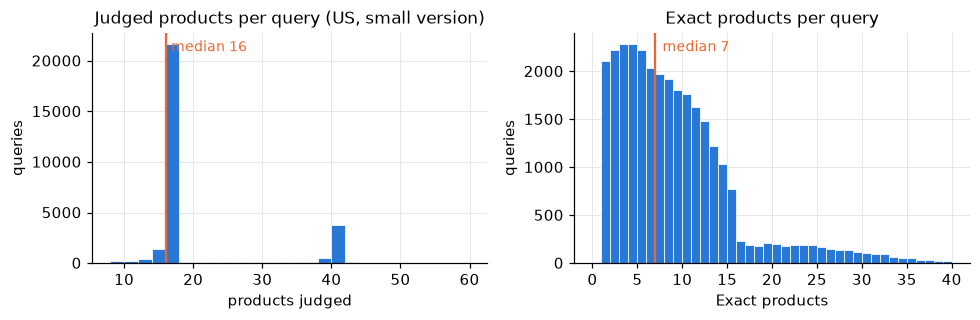

queries: 29,844  |  judged per query: mean 20.1, max 188  |  Exact per query: mean 8.8, median 7, zero Exact: 1 query


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(per_q.judged, bins=range(8, 61, 2), color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(title="Judged products per query (US, small version)", xlabel="products judged", ylabel="queries")
axes[1].hist(per_q.exact, bins=range(0, 41), color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set(title="Exact products per query", xlabel="Exact products", ylabel="queries")
for ax, s in zip(axes, (per_q.judged, per_q.exact)):
    ax.axvline(s.median(), color=ORANGE, linewidth=1.5)
    ax.text(s.median() + 0.8, ax.get_ylim()[1] * 0.92, f"median {s.median():.0f}", color=ORANGE, fontsize=9)
plt.tight_layout(); plt.show()
print(f"queries: {len(per_q):,}  |  judged per query: mean {per_q.judged.mean():.1f}, max {per_q.judged.max()}  |  "
      f"Exact per query: mean {per_q.exact.mean():.1f}, median {per_q.exact.median():.0f}, zero Exact: {(per_q.exact == 0).sum()} query")

In [4]:
# The product-disjoint split, computed from the judgements file alone (the same function runs on Modal to build the benchmark).
ex = esci.data.load_examples(RAW, LOCALE, VERSION)
train_j, dev_j, test_j, split_stats = esci.data.split_judgements(ex, dev_queries=500, seed=42)

official_test_products = set(ex[ex.split == "test"].product_id)
official_train_products = set(ex[ex.split == "train"].product_id)
overlap = official_test_products & official_train_products
test_exact = set(ex[(ex.split == "test") & (ex.esci_label == "E")].product_id)
print(f"official split: {split_stats['train_queries_official']:,} train queries, {ex[ex.split == 'test'].query_id.nunique():,} test queries")
print(f"products in test lists also in some training list: {len(overlap):,} of {len(official_test_products):,} "
      f"({len(overlap) / len(official_test_products):.1%}); among test Exact products: {len(overlap & test_exact) / len(test_exact):.1%}")
print(f"removing them drops {split_stats['train_judgements_removed_product_overlap']:,} of {split_stats['train_judgements_official']:,} "
      f"training judgements ({split_stats['train_judgements_removed_product_overlap'] / split_stats['train_judgements_official']:.1%}) "
      f"and {split_stats['train_queries_dropped_after_overlap_removal']} queries left with no Exact product")
print(f"test products still seen in the final training judgements: {split_stats['test_products_seen_in_final_train']}")

pd.DataFrame({k: {"queries": v["queries"], "judgements": v["judgements"], "distinct products": v["products"], "Exact pairs": v["exact_pairs"],
                  "Exact per query (mean)": v["exact_per_query_mean"], **{f"share {l}": v["label_share"][l] for l in "ESCI"}}
              for k, v in split_stats.items() if k in ("train", "dev", "test")}).T

official split: 20,888 train queries, 8,956 test queries
products in test lists also in some training list: 34,756 of 164,900 (21.1%); among test Exact products: 20.7%
removing them drops 66,945 of 419,653 training judgements (16.0%) and 338 queries left with no Exact product
test products still seen in the final training judgements: 0


,queries,judgements,distinct products,Exact pairs,Exact per query (mean),share E,share S,share C,share I
train,20039.0,341147.0,308055.0,153467.0,7.66,0.450,0.346,0.046,0.158
dev,500.0,8621.0,8584.0,3762.0,7.52,0.436,0.355,0.050,0.158
test,8955.0,181686.0,164887.0,79708.0,8.90,0.439,0.350,0.045,0.167


## 4. The metrics, defined on one query

All metrics are computed per query over the whole corpus and then averaged over queries. For one query with the
set of Exact products $E$ and a ranked list $r_1, r_2, \dots$:

- **recall@k** $= |\{r_1..r_k\} \cap E| \,/\, |E|$. The headline. With 9 Exact products on average, recall@20 of
  0.5 means "half of the right products are in the candidate set".
- **hit@k** $= 1$ if any Exact product is in the top $k$. The weakest useful guarantee: the reranker has at least
  one right answer to find. (Also called accuracy@k or success@k.)
- **MRR@k**, Mean Reciprocal Rank $= 1/\text{rank of the first Exact product}$, 0 if none in the top $k$.
- **nDCG@k**, normalized Discounted Cumulative Gain: each product at rank $i$ contributes
  $\text{gain}/\log_2(i+1)$, with the KDD Cup gains E = 1.0, S = 0.1, C = 0.01, I = 0, divided by the best
  achievable value for that query. It gives partial credit for substitutes and rewards putting Exact products
  early. It is the right number for the *final* list, so it lives in the reports but not in the headlines.

Products a ranking returns that were **never judged** for that query get gain 0 and do not count as Exact. Every
system is penalised equally for finding a good product the annotators never saw, so comparisons between systems
are fair, but the absolute numbers are a floor, not the truth. `esci/metrics.py` implements all of this and is shared by
BM25, the dense models and the hybrid, so no two systems can be scored differently by accident.

In [5]:
# A worked example on a real test query with a made-up ranking.
qid = per_q[(per_q.exact == 4) & (per_q.judged == 16)].sample(1, random_state=3).index[0]
labels_q = dict(zip(test_j[test_j.query_id == qid].product_id, test_j[test_j.query_id == qid].esci_label)) or \
           dict(zip(ex[ex.query_id == qid].product_id, ex[ex.query_id == qid].esci_label))
exact = [p for p, l in labels_q.items() if l == "E"]; subs = [p for p, l in labels_q.items() if l == "S"]; irr = [p for p, l in labels_q.items() if l == "I"]
print(f"query {qid}: {per_q.loc[qid, 'query']!r}  →  {len(exact)} Exact, {len(subs)} Substitute, {len(irr)} Irrelevant judged")

toy = {qid: [subs[0], exact[0], "UNJUDGED-1", irr[0], exact[1], "UNJUDGED-2", "UNJUDGED-3", "UNJUDGED-4", "UNJUDGED-5", exact[2]]}
print("toy ranking:", ["S", "E", "?", "I", "E", "?", "?", "?", "?", "E"], "(E/S/I = label of the product at that rank, ? = never judged)")
r = esci.metrics.evaluate(toy, {qid: labels_q}, ks=(5, 10))
pd.Series(r["metrics"]).drop("queries").round(3).to_frame("value").T

query 114882: 'yellow pepper'  →  4 Exact, 3 Substitute, 9 Irrelevant judged
toy ranking: ['S', 'E', '?', 'I', 'E', '?', '?', '?', '?', 'E'] (E/S/I = label of the product at that rank, ? = never judged)


,recall@5,hit@5,mrr@5,ndcg@5,recall@10,hit@10,mrr@10,ndcg@10
value,0.5,1.0,0.5,0.43,0.75,1.0,0.5,0.527


By hand: 4 Exact products exist; 2 are in the top 5 (ranks 2 and 5) → recall@5 = 0.5; 3 are in the top 10 → recall@10 = 0.75;
the first Exact sits at rank 2 → MRR = 0.5 at both cutoffs; hit = 1 at both. nDCG@10 is below recall@10 because
the Exact products sit at ranks 2, 5 and 10 rather than 1, 2 and 3, and the substitute at rank 1 earns only 0.1.

## 5. Building the benchmark on Modal

Product text lives in the 1.1 GB products file, which this Mac never downloads. `modal_esci.build_data` fetches both
raw files into the Modal Volume `esci-data` (verified against the repository's checksums), applies
`esci.data.split_judgements` exactly as above, attaches the text and writes the benchmark next to the GPU:

- `corpus.parquet`: 482k products. The **passage** an embedding model sees is the title, a `Brand: …, Color: …`
  line and the bullet points, whitespace-collapsed and cut at 1,200 characters (about 250 tokens). The product
  description is left out in this version: it is long, often HTML, and mostly repeats the bullets; adding it is
  a flag to test later, not an assumption to bake in.
- `train_judgements.parquet`, `dev_judgements.parquet`, `test_judgements.parquet`: the product-disjoint split.
- `dev_corpus_ids.json`: the dev queries' judged products plus random fillers, 20k products in all. The trainer
  re-encodes its evaluation corpus every epoch, so it gets this sub-corpus; the 482k-product corpus is encoded
  once per model at the end.
- `stats.json`, plus two small files for this notebook: a 10k-product sample and the full judged lists of 25
  test queries with text.

Only those small files (about 20 MB) come back to `data/processed/us-small/`. The build is a CPU job: 4 cores,
16 GB, a few minutes, a few cents.

In [6]:
from jobs import modal_esci
from jobs.common import modal_once   # runs a Modal job once: a saved outputs/<run>/report.json is read back instead of paying again

t0 = time.time()
if not (PROCESSED / "stats.json").exists():
    with modal_esci.app.run():
        stats = modal_esci.build_data.remote(locale=LOCALE, version=VERSION, dev_queries=500, seed=42)
    modal_esci.download_benchmark(LOCALE, VERSION)
    print(f"benchmark built and small files downloaded in {(time.time() - t0) / 60:.1f} min; container {stats['wall_seconds']:.0f}s, "
          f"estimated cost ${modal_esci.est_cost(stats['wall_seconds'], None, 4, 16):.3f}")
stats = json.loads((PROCESSED / "stats.json").read_text())
assert stats["test_products_seen_in_final_train"] == 0
print(f"corpus: {stats['corpus']['products']:,} products | passage length: mean {stats['corpus']['text_chars_mean']:.0f} chars, "
      f"median {stats['corpus']['text_chars_median']:.0f}, cut at {stats['passage_max_chars']}: {stats['corpus']['share_cut_at_max_chars']:.1%} | "
      f"with brand {stats['corpus']['share_with_brand']:.1%}, with bullets {stats['corpus']['share_with_bullets']:.1%} | "
      f"products missing from the products file: {stats['corpus_products_missing_from_products_file']}")

corpus: 482,105 products | passage length: mean 653 chars, median 617, cut at 1200: 20.7% | with brand 94.4%, with bullets 86.8% | products missing from the products file: 0


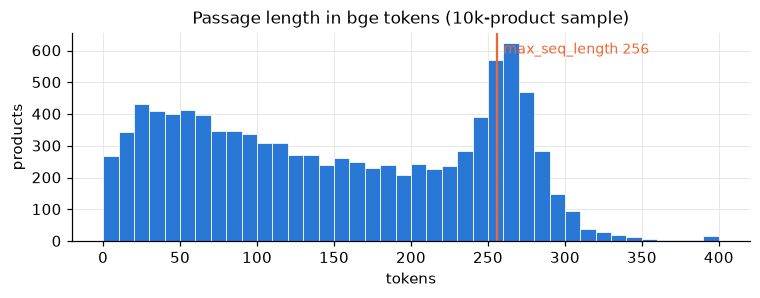

tokens per passage: median 146, mean 152, 90th pct 272, longer than 256: 19.6%

test query: 'ant man'  (11 E, 5 S, 0 C, 0 I)
  [E] Ant-Man 2 Film Collection (Ant-Man/Ant-Man and the Wasp)
  [E] Ant-Man and the Wasp (4K UHD)
  [E] Ant-Man and Ant-Man and the Wasp Double Pack (Blu-Ray) | Brand: Marvel | Blu-Ray
  [E] ANT-MAN AND THE WASP [Blu-ray] | Brand: Marvel | Brand New in box. The product ships with all relevant accessories
  [E] Ant-Man and the Wasp (Plus Bonus Content)
  [E] Ant-Man and the Wasp
  [E] Avengers Marvel Legends Series 6-inch Ant-Man | Brand: Avengers, Color: Brown/a | Movie-inspired design Premium articulation and detailing [...]
  [E] Ant-Man (Theatrical)
  [E] Ant-Man (Plus Bonus Features)
  [E] Ant-Man (1-Disc DVD) | Brand: Walt Disney Studios | DVD Multiple Formats, AC-3, Color Spanish (Published), French (Subtitled), Spanish [...]
  [E] Marvel Ant-Man and the Wasp Shrink and Strike Ant-Man | Brand: Marvel, Color: Red | 12-inch Ant-Man figure featuring load & la

In [7]:
from tokenizers import Tokenizer
tok = Tokenizer.from_pretrained(MODEL_ID)   # the tokenizer file only (700 KB), to count tokens; no model weights

sample = pd.read_parquet(PROCESSED / "corpus_sample.parquet")
examples = pd.read_parquet(PROCESSED / "test_examples.parquet")
n_tokens = pd.Series([len(e.ids) for e in tok.encode_batch(sample.text.tolist())])

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(n_tokens.clip(upper=400), bins=range(0, 401, 10), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(256, color=ORANGE, linewidth=1.5); ax.text(260, ax.get_ylim()[1] * 0.9, "max_seq_length 256", color=ORANGE, fontsize=9)
ax.set(title="Passage length in bge tokens (10k-product sample)", xlabel="tokens", ylabel="products")
plt.tight_layout(); plt.show()
print(f"tokens per passage: median {n_tokens.median():.0f}, mean {n_tokens.mean():.0f}, 90th pct {n_tokens.quantile(.9):.0f}, "
      f"longer than 256: {(n_tokens > 256).mean():.1%}")

q = examples.query_id.unique()[2]
g = examples[examples.query_id == q].sort_values("esci_label", key=lambda s: s.map({"E": 0, "S": 1, "C": 2, "I": 3}))
print(f"\ntest query: {g['query'].iloc[0]!r}  ({(g.esci_label == 'E').sum()} E, {(g.esci_label == 'S').sum()} S, "
      f"{(g.esci_label == 'C').sum()} C, {(g.esci_label == 'I').sum()} I)")
for _, row in g.iterrows():
    print(f"  [{row.esci_label}] {textwrap.shorten(str(row.text).replace(chr(10), ' | '), 150)}")

## 6. Baselines: lexical, dense and hybrid, on Modal

Three retrievers, all scored on the same slice with the same evaluator and rankings saved to depth 100:

- **BM25** (Best Match 25): the term-weighting formula behind classic search engines. A product scores high
  when it contains the query's words, rare words count more, and long documents are normalised down. No model,
  no training, CPU only; the `bm25s` implementation with English stopwords and a Snowball stemmer. On shopping
  queries it is a serious opponent: "ethika", "fiestaware teapot", "iphone 11 otterbox" are solved by matching the
  rare word, and a dense model can blur exactly those.
- **Dense retrieval with `bge-base-en-v1.5` off the shelf**: encode every passage once (no query prefix),
  encode the query with the model's prefix, rank by cosine similarity. Runs on an A10G GPU.
- **Hybrid**: Reciprocal Rank Fusion (RRF) of the two rankings, score $= \sum 1/(60 + \text{rank})$. Rank-based,
  so BM25 scores and cosines never need to be put on one scale. This is the shape most production systems have,
  and it is what the fine-tuned model will be plugged into.

Then the "does size beat domain" column: `bge-large-en-v1.5` (335M parameters, same family), and
`Qwen3-Embedding-0.6B` and `Qwen3-Embedding-8B` (top of the MTEB leaderboard, the Massive Text Embedding
Benchmark) with a shopping-specific instruction on the query side, on an L40S (48 GB) so the 8B model fits in
bfloat16.

**Cost control.** Encoding is the expensive part and it scales with corpus size × model size, so every
configuration is first run on a **smoke slice**: 500 random test queries and a 20,000-product corpus made of those
queries' judged products (about 10k) plus random fillers. The smoke run checks the pipeline end to end,
gives measured encode throughput per model, and that throughput prices the full run before it is launched.
Each Modal cell is wrapped in `modal_once`, which reads a saved report back rather than paying twice.

In [8]:
SMOKE = dict(corpus_limit=20_000, max_test_queries=500)
QWEN = ["Qwen/Qwen3-Embedding-0.6B", "Qwen/Qwen3-Embedding-8B"]

t0 = time.time()
with modal_esci.app.run():
    launch = lambda name, models, gpu, bs: (lambda: modal_esci.evaluate_dense.with_options(gpu=gpu).remote(
        run_name=name, models=models, locale=LOCALE, version=VERSION, corpus_limit=SMOKE["corpus_limit"], max_test_queries=SMOKE["max_test_queries"],
        encode_batch_size=bs, seed=42))
    smoke_dense = modal_once("baselines-smoke", launch("baselines-smoke", [MODEL_ID], "A10G", 256))
    smoke_qwen = modal_once("compare-smoke", launch("compare-smoke", QWEN, "L40S", 64))
    files = [f"baselines-smoke/{r['rankings_file']}" for r in smoke_dense["results"].values()]
    smoke_lex = modal_once("baselines-smoke-bm25", lambda: modal_esci.bm25_and_hybrid.remote(
        run_name="baselines-smoke-bm25", locale=LOCALE, version=VERSION, dense_rankings=files, corpus_limit=SMOKE["corpus_limit"],
        max_test_queries=SMOKE["max_test_queries"], seed=42))
print(f"smoke runs done in {(time.time() - t0) / 60:.1f} min\n")

KEEP = ["recall@10", "recall@20", "recall@50", "hit@20", "mrr@20", "ndcg@20"]
def rows(report, gpu, cpu=0, mem=0):
    out = []
    for label, r in report["results"].items():
        out.append({"system": label, "params (M)": r.get("params_M"), **{k: round(r["metrics"][k], 3) for k in KEEP},
                    "corpus encode (s)": r.get("encode_corpus_seconds", r.get("index_seconds")), "corpus": r["corpus_products"],
                    "queries": r["metrics"]["queries"]})
    secs = report.get("container_seconds", report.get("wall_seconds"))
    print(f"{report['run_name']:24s} container {secs:6.0f}s on {gpu or f'{cpu} CPU cores':12s} ≈ ${modal_esci.est_cost(secs, gpu, cpu, mem):.3f} at list price")
    return out

smoke = pd.DataFrame(rows(smoke_lex, None, 8, 32) + rows(smoke_dense, "A10G") + rows(smoke_qwen, "L40S")).set_index("system")
smoke

baselines-smoke: using the saved report at outputs/baselines-smoke/report.json
compare-smoke: using the saved report at outputs/compare-smoke/report.json
baselines-smoke-bm25: using the saved report at outputs/baselines-smoke-bm25/report.json
smoke runs done in 0.0 min

baselines-smoke-bm25     container      5s on 8 CPU cores  ≈ $0.001 at list price
baselines-smoke          container     29s on A10G         ≈ $0.009 at list price
compare-smoke            container    465s on L40S         ≈ $0.252 at list price


,params (M),recall@10,recall@20,recall@50,hit@20,mrr@20,ndcg@20,corpus encode (s),corpus,queries
system,,,,,,,,,,
bm25,0.0,0.500,0.663,0.784,0.920,0.678,0.586,1.6,20000,500
hybrid(bm25+BAAI__bge-base-en-v1.5),NaN,0.546,0.712,0.861,0.946,0.713,0.632,NaN,20000,500
BAAI/bge-base-en-v1.5,109.5,0.543,0.717,0.851,0.950,0.725,0.637,14.9,20000,500
Qwen/Qwen3-Embedding-0.6B,595.8,0.515,0.688,0.821,0.940,0.681,0.603,54.2,20000,500
Qwen/Qwen3-Embedding-8B,7567.3,0.577,0.761,0.885,0.944,0.739,0.676,377.1,20000,500


In [9]:
# Price the full benchmark from the measured smoke throughput: encode time scales with corpus size.
for report, gpu in ((smoke_dense, "A10G"), (smoke_qwen, "L40S")):
    for label, r in report["results"].items():
        scale = stats["corpus"]["products"] / r["corpus_products"]
        full_s = r["load_seconds"] + r["encode_corpus_seconds"] * scale + r["queries_and_search_seconds"] * (stats["test"]["queries"] / SMOKE["max_test_queries"])
        print(f"{label:28s} {r['encode_corpus_seconds'] / r['corpus_products'] * 1000:5.1f} s per 1k products on {gpu}  →  "
              f"full corpus ≈ {full_s / 60:5.1f} min ≈ ${modal_esci.est_cost(full_s, gpu):.2f}")

BAAI/bge-base-en-v1.5          0.7 s per 1k products on A10G  →  full corpus ≈   6.0 min ≈ $0.11
Qwen/Qwen3-Embedding-0.6B      2.7 s per 1k products on L40S  →  full corpus ≈  22.0 min ≈ $0.71
Qwen/Qwen3-Embedding-8B       18.9 s per 1k products on L40S  →  full corpus ≈ 152.1 min ≈ $4.94


In [10]:
# The full benchmark: all 8,955 test queries over all 482k products.
# Qwen3 0.6B + 8B on an L40S (the long job, ~2.5 h, spawned first so it runs in parallel), bge-base and bge-large on an A10G,
# then BM25 + hybrid on CPU (it needs the dense rankings). Each run is priced in the cell above; RUN_FULL_QWEN gates the big one.
RUN_FULL_QWEN = True
FULL = dict(corpus_limit=0, max_test_queries=0)

t0 = time.time()
with modal_esci.app.run():
    launch = lambda name, models, gpu, bs: (lambda: modal_esci.evaluate_dense.with_options(gpu=gpu).remote(
        run_name=name, models=models, locale=LOCALE, version=VERSION, corpus_limit=FULL["corpus_limit"], max_test_queries=FULL["max_test_queries"],
        encode_batch_size=bs, seed=42))
    qwen_job = None
    if RUN_FULL_QWEN and not (OUT / "compare-qwen" / "report.json").exists():
        qwen_job = modal_esci.evaluate_dense.with_options(gpu="L40S").spawn(run_name="compare-qwen", models=QWEN, locale=LOCALE, version=VERSION,
                                                                           encode_batch_size=64, seed=42)
    full_dense = modal_once("baselines-us-small", launch("baselines-us-small", [MODEL_ID, "BAAI/bge-large-en-v1.5"], "A10G", 256))
    files = [f"baselines-us-small/{full_dense['results'][MODEL_ID]['rankings_file']}"]
    full_lex = modal_once("baselines-us-small-bm25", lambda: modal_esci.bm25_and_hybrid.remote(
        run_name="baselines-us-small-bm25", locale=LOCALE, version=VERSION, dense_rankings=files, corpus_limit=FULL["corpus_limit"],
        max_test_queries=FULL["max_test_queries"], seed=42))
    full_qwen = modal_once("compare-qwen", lambda: qwen_job.get()) if (qwen_job or (OUT / "compare-qwen" / "report.json").exists()) else None
print(f"full runs done in {(time.time() - t0) / 60:.1f} min\n")

full = pd.DataFrame(rows(full_lex, None, 8, 32) + rows(full_dense, "A10G") + (rows(full_qwen, "L40S") if full_qwen else [])).set_index("system")
full

baselines-us-small: using the saved report at outputs/baselines-us-small/report.json
baselines-us-small-bm25: using the saved report at outputs/baselines-us-small-bm25/report.json
compare-qwen: using the saved report at outputs/compare-qwen/report.json
full runs done in 0.0 min

baselines-us-small-bm25  container     95s on 8 CPU cores  ≈ $0.017 at list price
baselines-us-small       container   1516s on A10G         ≈ $0.463 at list price
compare-qwen             container  10329s on L40S         ≈ $5.595 at list price


,params (M),recall@10,recall@20,recall@50,hit@20,mrr@20,ndcg@20,corpus encode (s),corpus,queries
system,,,,,,,,,,
bm25,0.0,0.292,0.383,0.497,0.748,0.465,0.337,66.4,482105,8955
hybrid(bm25+BAAI__bge-base-en-v1.5),NaN,0.331,0.437,0.570,0.803,0.525,0.385,NaN,482105,8955
BAAI/bge-base-en-v1.5,109.5,0.320,0.421,0.544,0.794,0.510,0.370,354.8,482105,8955
BAAI/bge-large-en-v1.5,335.1,0.332,0.436,0.563,0.801,0.520,0.384,1135.7,482105,8955
Qwen/Qwen3-Embedding-0.6B,595.8,0.280,0.376,0.502,0.761,0.467,0.332,1287.5,482105,8955
Qwen/Qwen3-Embedding-8B,7567.3,0.341,0.455,0.595,0.817,0.532,0.401,8979.2,482105,8955


## 7. Results

In [11]:
NAMES = {"bm25": "BM25 (lexical, no model)", MODEL_ID: "bge-base-en-v1.5, off the shelf", "BAAI/bge-large-en-v1.5": "bge-large-en-v1.5, off the shelf",
         "Qwen/Qwen3-Embedding-0.6B": "Qwen3-Embedding-0.6B, off the shelf", "Qwen/Qwen3-Embedding-8B": "Qwen3-Embedding-8B, off the shelf",
         "hybrid(bm25+BAAI__bge-base-en-v1.5)": "hybrid: BM25 + bge-base (RRF)"}
order = ["bm25", MODEL_ID, "hybrid(bm25+BAAI__bge-base-en-v1.5)", "BAAI/bge-large-en-v1.5", "Qwen/Qwen3-Embedding-0.6B", "Qwen/Qwen3-Embedding-8B"]

def table(df):
    d = df.reindex([o for o in order if o in df.index]).rename(index=NAMES)
    return d[["params (M)"] + KEEP + ["corpus encode (s)"]]

print(f"FULL benchmark: {int(full['queries'].iloc[0]):,} test queries, corpus {int(full['corpus'].iloc[0]):,} products")
display(table(full))
print(f"\nSMOKE slice: {int(smoke['queries'].iloc[0]):,} test queries, corpus {int(smoke['corpus'].iloc[0]):,} products (easier: a 24× smaller haystack)")
table(smoke)

FULL benchmark: 8,955 test queries, corpus 482,105 products


,params (M),recall@10,recall@20,recall@50,hit@20,mrr@20,ndcg@20,corpus encode (s)
system,,,,,,,,
"BM25 (lexical, no model)",0.0,0.292,0.383,0.497,0.748,0.465,0.337,66.4
"bge-base-en-v1.5, off the shelf",109.5,0.320,0.421,0.544,0.794,0.510,0.370,354.8
hybrid: BM25 + bge-base (RRF),NaN,0.331,0.437,0.570,0.803,0.525,0.385,NaN
"bge-large-en-v1.5, off the shelf",335.1,0.332,0.436,0.563,0.801,0.520,0.384,1135.7
"Qwen3-Embedding-0.6B, off the shelf",595.8,0.280,0.376,0.502,0.761,0.467,0.332,1287.5
"Qwen3-Embedding-8B, off the shelf",7567.3,0.341,0.455,0.595,0.817,0.532,0.401,8979.2



SMOKE slice: 500 test queries, corpus 20,000 products (easier: a 24× smaller haystack)


,params (M),recall@10,recall@20,recall@50,hit@20,mrr@20,ndcg@20,corpus encode (s)
system,,,,,,,,
"BM25 (lexical, no model)",0.0,0.500,0.663,0.784,0.920,0.678,0.586,1.6
"bge-base-en-v1.5, off the shelf",109.5,0.543,0.717,0.851,0.950,0.725,0.637,14.9
hybrid: BM25 + bge-base (RRF),NaN,0.546,0.712,0.861,0.946,0.713,0.632,NaN
"Qwen3-Embedding-0.6B, off the shelf",595.8,0.515,0.688,0.821,0.940,0.681,0.603,54.2
"Qwen3-Embedding-8B, off the shelf",7567.3,0.577,0.761,0.885,0.944,0.739,0.676,377.1


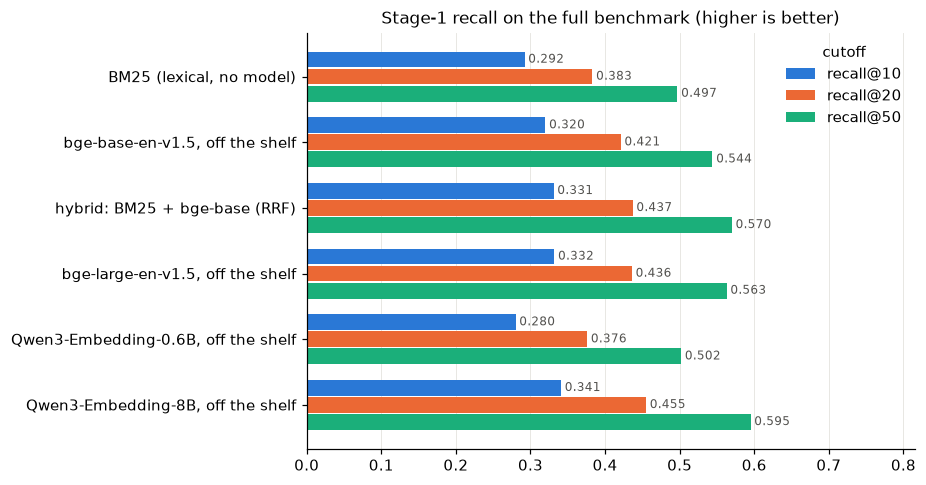

In [12]:
d = table(full)
ks = ["recall@10", "recall@20", "recall@50"]
fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(d) + 1.2))
y = np.arange(len(d))
for i, (k, c) in enumerate(zip(ks, (BLUE, ORANGE, AQUA))):
    ax.barh(y + (i - 1) * 0.26, d[k], height=0.24, color=c, label=k)
    for yy, v in zip(y + (i - 1) * 0.26, d[k]):
        ax.text(v + 0.005, yy, f"{v:.3f}", va="center", fontsize=8, color="#52514e")
ax.set(yticks=y, yticklabels=d.index, xlim=(0, d[ks].max().max() + 0.22), title="Stage-1 recall on the full benchmark (higher is better)")
ax.invert_yaxis(); ax.legend(frameon=False, loc="upper right", title="cutoff"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [13]:
# Where does BM25 beat the dense model, and the other way round? Per-query recall@20 from the saved rankings.
pq = {}
for run, label in (("baselines-us-small-bm25", "bm25"), ("baselines-us-small", "BAAI__bge-base-en-v1.5"), ("baselines-us-small-bm25", "hybrid(bm25+BAAI__bge-base-en-v1.5)")):
    pq[label] = pd.read_parquet(OUT / run / "rankings" / f"{label}.per_query.parquet").set_index("query_id")["recall@20"]
pq = pd.DataFrame(pq).rename(columns={"BAAI__bge-base-en-v1.5": "dense", "hybrid(bm25+BAAI__bge-base-en-v1.5)": "hybrid"})
queries = esci.data.queries_of(pd.read_parquet(PROCESSED / "test_judgements.parquet")).set_index("query_id")["query"]
pq["query"] = queries
diff = pq.dense - pq.bm25
print(f"queries where dense beats BM25 on recall@20: {(diff > 0).mean():.1%} | BM25 beats dense: {(diff < 0).mean():.1%} | tie: {(diff == 0).mean():.1%}")
print(f"hybrid beats both: {((pq.hybrid > pq.dense) & (pq.hybrid > pq.bm25)).mean():.1%} | hybrid is worse than the better one: {(pq.hybrid < pq[['dense', 'bm25']].max(axis=1)).mean():.1%}")
print(f"queries where nobody finds a single Exact product in the top 20: {(pq[['bm25', 'dense', 'hybrid']].max(axis=1) == 0).mean():.1%}")

pd.set_option("display.max_colwidth", 60)
print("\nBM25 wins by the most (exact words carry the query):"); display(pq.loc[diff.nsmallest(8).index, ["query", "bm25", "dense", "hybrid"]].round(2))
print("dense wins by the most (meaning over words):"); pq.loc[diff.nlargest(8).index, ["query", "bm25", "dense", "hybrid"]].round(2)

queries where dense beats BM25 on recall@20: 34.2% | BM25 beats dense: 24.0% | tie: 41.8%
hybrid beats both: 11.5% | hybrid is worse than the better one: 28.5%
queries where nobody finds a single Exact product in the top 20: 14.1%

BM25 wins by the most (exact words carry the query):


,query,bm25,dense,hybrid
query_id,,,,
351,.5 inch suction cups without hooks,1.0,0.0,0.0
1310,10 succulent plants without plastic containers,1.0,0.0,0.0
1731,11.5 x 8 clear plastic bux,1.0,0.0,0.0
3771,36 world's softest bear,1.0,0.0,1.0
6433,acrylic toilet seat elongated,1.0,0.0,0.0
7034,aeramax 290 small room,1.0,0.0,1.0
7132,aga stove,1.0,0.0,0.0
10332,armani clasic shoes for men,1.0,0.0,1.0


dense wins by the most (meaning over words):


,query,bm25,dense,hybrid
query_id,,,,
858,1 peter jen wilkin,0.0,1.0,1.0
1756,112 aio cooler without fans,0.0,1.0,0.0
2359,"18"" chair cushions for dining room",0.0,1.0,0.0
4142,"4"" non marking caster wheel",0.0,1.0,0.0
4163,40 cake pan,0.0,1.0,0.0
4299,49ers gym apparel,0.0,1.0,1.0
5274,8 month old towels,0.0,1.0,1.0
5539,952 yellow xl,0.0,1.0,0.0


## 8. What this sets up for notebook 02

The table above is the bar the fine-tuned 110M model has to clear, and the fixed test harness it will be scored
on: the same 8,955 product-disjoint test queries, the same 482k-product corpus, rankings to depth 100 in the
same file format, so the reranker and the hybrid can be built on top of any of them.

What notebook 02 will do with the training half of the data:

- **Pairs and negatives from the judgements**: (query, Exact product) pairs, up to 3 per query, each with one
  negative. The labelled Substitute/Complement/Irrelevant products are negatives a human already confirmed are
  not Exact; the alternative is *mining* them (the base model's top-ranked non-Exact products, which may include
  unjudged true positives). `esci/embed_train.py --negatives {labelled,substitutes,mined,random,none}` makes that a
  measured comparison rather than a belief.
- **The in-training check on the dev set and its 20k sub-corpus**, the full test evaluation once at the end.
- **The same columns**: BM25, hybrid with the fine-tuned model in place of the base model, and the bigger models.

And after that: a cross-encoder reranker trained on the same triples, scored on nDCG at small cutoffs over the
top 20 that this stage produces.

## 9. Gotchas

- **"Small" is a flag, not a file.** Both versions live in the same 51 MB examples file; the product text is one
  1.1 GB file for all locales. Filter by `product_locale` and `small_version`, then join on
  (`product_locale`, `product_id`): the same product id can exist in several locales with different text.
- **Query-disjoint is not product-disjoint.** The official split keeps test queries unseen but about one test
  product in five appears in training lists. Decide what "unseen" has to mean for your use case before training.
- **Sparse judgements make absolute numbers a floor.** Each query has about 20 judged products out of 482k.
  Any system finding a good unjudged product is penalised for it, equally. Compare systems; do not quote
  recall@20 as "how often the customer sees the right product".
- **Encode cost is corpus × model, every time the model changes.** A fine-tuned model means re-encoding the whole
  catalogue; the smoke slice prices that before it is paid.
- **Prompts are part of the model.** bge wants its prefix on queries only; Qwen3-Embedding wants a one-line
  task instruction on queries only. Encoding passages with the prefix, or queries without it, costs points silently.
- **Keep ranking files, not just metrics.** Every analysis in §7, the hybrid, and the reranker's training data
  come from the saved top-100 lists; the metrics alone would allow none of them.